# Parte de la protección social pagada con impuestos

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "financiacion-impuestos-proteccion-social"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Parte de la protección social pagada con impuestos"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de los ingresos de la protección social"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** De cada 100 euros que ingresan los sistemas de protección social de un país, cuántos son aportaciones de las administraciones públicas, es decir, impuestos (generales o asignados a un fin) y no cotizaciones sociales. El resto son, sobre todo, las cotizaciones de empresas y trabajadores y, en pequeña parte, otros ingresos (rentas de la propiedad, por ejemplo).

**Cómo se lee.** Un valor de 40 significa que el 40 % de los ingresos de la protección social de ese año fueron aportaciones de las administraciones públicas pagadas con impuestos; el 60 % restante, sobre todo cotizaciones. Una subida indica que el sistema depende más de los impuestos generales y menos de las cotizaciones.

**Limitaciones.**
- **No es solo la Seguridad Social.** La fuente es el sistema europeo de estadísticas de protección social (ESSPROS), que cubre toda la protección social: pensiones, desempleo, familia, incapacidad, vivienda y exclusión social, pero también la **sanidad**, que en España se paga con impuestos desde finales de los noventa. Por eso el porcentaje no mide cuánto de las pensiones pagan las cotizaciones; para eso sirve, con sus propias limitaciones, `saldo-seguridad-social`.
- **Solo Europa.** ESSPROS no existe fuera de Europa y la base de gasto social de la OCDE (SOCX) solo publica gastos, no ingresos: las series de la OCDE, Estados Unidos y Canadá quedan vacías.
- La media de la UE-27 empieza en 2008, primer año que publica Eurostat para el agregado.

## 2. Descarga

Eurostat, ingresos de los sistemas de protección social por tipo (`spr_rec_sumt`, ESSPROS), en % de los ingresos totales (`PC_REC`), España y UE-27:
- `GOV_GEN`: aportaciones de las administraciones públicas (la serie de la gráfica), suma de `GOV_GEN_EM` (impuestos asignados) y `GOV_GEN_REVGEN` (recursos generales).
- `SCO`: cotizaciones sociales, suma de `SCO_EMPL` (de los empleadores) y `SCO_PER_PRO` (de las personas protegidas: trabajadores, autónomos y pensionistas). Solo para el desglose de la sección 3.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, oecd
from lib.tipos import FuenteMeta

DATASET = "spr_rec_sumt"
TIPOS = ["GOV_GEN", "GOV_GEN_EM", "GOV_GEN_REVGEN", "SCO", "SCO_EMPL", "SCO_PER_PRO"]
partes, fuentes_gov = {}, None
for tipo in TIPOS:
    d, f = eurostat.get(DATASET, {"freq": "A", "sptype": tipo, "unit": "PC_REC"}, desde=DESDE)
    partes[tipo] = d
    if tipo == "GOV_GEN":
        fuentes_gov = f
print({t: sorted(d["serie"].unique()) for t, d in partes.items()})

{'GOV_GEN': ['espana', 'ue27'], 'GOV_GEN_EM': ['espana', 'ue27'], 'GOV_GEN_REVGEN': ['espana', 'ue27'], 'SCO': ['espana', 'ue27'], 'SCO_EMPL': ['espana', 'ue27'], 'SCO_PER_PRO': ['espana', 'ue27']}


## 3. Transformación

La serie de la gráfica es `GOV_GEN` tal como la publica Eurostat. Se comprueba que es la suma de sus dos partes y se muestra el desglose; la OCDE, EE. UU. y Canadá quedan en `null`.

In [ ]:
df = partes["GOV_GEN"]
HOY = fuentes_gov[0].fecha_consulta
fuentes = [
    FuenteMeta(f.serie, f.organismo, f"{DATASET} (sptype=GOV_GEN, unit=PC_REC)", f.url, f.fecha_consulta)
    for f in fuentes_gov
]


def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, HOY) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]


SOCX = (oecd.ORGANISMO, "Social Expenditure Database (SOCX): solo publica gastos, no ingresos", oecd.URL_EXPLORER)
df, fuentes = anadir_sin_dato(df, fuentes, {"ocde": SOCX, "eeuu": SOCX, "canada": SOCX})


def tabla(geo):
    t = pd.DataFrame({k: d[d["serie"] == geo].set_index("periodo")["valor"] for k, d in partes.items()})
    t["GOV_GEN − (EM + REVGEN)"] = t["GOV_GEN"] - t[["GOV_GEN_EM", "GOV_GEN_REVGEN"]].sum(axis=1, min_count=1)
    t["otros ingresos"] = 100 - t["GOV_GEN"] - t["SCO"]
    return t


desglose = {g: tabla(g) for g in ("espana", "ue27")}
for g, t in desglose.items():
    assert t["GOV_GEN − (EM + REVGEN)"].abs().max() < 0.05, f"{g}: GOV_GEN no es la suma de sus partes"
    print(g)
    display(t.round(2).iloc[::4])

espana


,GOV_GEN,GOV_GEN_EM,GOV_GEN_REVGEN,SCO,SCO_EMPL,SCO_PER_PRO,GOV_GEN − (EM + REVGEN),otros ingresos
periodo,,,,,,,,
1990,26.18,0.0,26.18,71.28,54.42,16.86,0.0,2.54
1994,28.37,0.0,28.37,69.52,51.51,18.01,0.0,2.11
1998,28.11,0.0,28.11,68.67,51.53,17.14,0.0,3.22
2002,32.52,0.0,32.52,65.31,51.11,14.20,0.0,2.17
2006,34.58,0.0,34.58,63.29,49.27,14.02,0.0,2.13
2010,43.30,0.0,43.30,55.22,42.94,12.28,0.0,1.48
2014,44.06,0.0,44.06,53.32,40.62,12.70,0.0,2.62
2018,39.69,NaN,39.69,59.14,45.83,13.32,0.0,1.17
2022,45.22,NaN,45.22,54.46,42.83,11.63,0.0,0.32


ue27


,GOV_GEN,GOV_GEN_EM,GOV_GEN_REVGEN,SCO,SCO_EMPL,SCO_PER_PRO,GOV_GEN − (EM + REVGEN),otros ingresos
periodo,,,,,,,,
2008,36.57,5.49,31.08,59.64,38.69,20.94,0.00,3.79
2012,38.82,5.74,33.08,57.76,36.81,20.94,0.00,3.42
2016,38.81,5.49,33.32,57.82,36.30,21.52,0.00,3.37
2020,42.69,6.30,36.38,54.31,33.87,20.45,0.01,3.00
2024,40.97,6.34,34.63,55.75,34.98,20.77,0.00,3.28


### Notas

Una frase por decisión. Las cifras de las notas salen de los datos anteriores.

In [ ]:
def fmt(x, decimales=1):
    return estilos.formato_es(x, decimales).replace("-", "−")


es = desglose["espana"]
ULT = int(es["GOV_GEN"].dropna().index.max())
ULT_EM = int(es["GOV_GEN_EM"].dropna().index.max())
OTROS_MAX = max(t["otros ingresos"].max() for t in desglose.values())
ue = desglose["ue27"]
NOTAS = [
    "España y UE-27: Eurostat, ingresos de los sistemas de protección social (ESSPROS, spr_rec_sumt), aportaciones "
    "de las administraciones públicas (GOV_GEN) en % de los ingresos totales. Media UE-27: agregado de composición "
    "actual (EU27_2020).",
    "ESSPROS cubre toda la protección social, también la sanidad, que en España se paga con impuestos, y no solo la "
    "Seguridad Social: el porcentaje no mide cuánto de las pensiones pagan las cotizaciones (para eso, ver "
    "la gráfica del saldo de las cuentas de la Seguridad Social).",
    f"El resto de los ingresos son sobre todo cotizaciones sociales de empleadores y de personas protegidas; en {ULT}, "
    f"las de los empleadores eran el {fmt(es.loc[ULT, 'SCO_EMPL'])} % de los ingresos en España y el "
    f"{fmt(ue.loc[ULT, 'SCO_EMPL'])} % en la UE-27, y las de las personas protegidas, el "
    f"{fmt(es.loc[ULT, 'SCO_PER_PRO'])} % y el {fmt(ue.loc[ULT, 'SCO_PER_PRO'])} %. Los otros ingresos no superan "
    f"el {fmt(OTROS_MAX)} % en ningún año.",
    f"España no separa los impuestos asignados a la protección social (GOV_GEN_EM, cero hasta {ULT_EM} y sin dato "
    f"después): todas sus aportaciones públicas son recursos generales.",
    "OCDE, EE. UU. y Canadá: sin dato. ESSPROS es un sistema europeo y la base de gasto social de la OCDE (SOCX) "
    "solo publica gastos, no ingresos.",
]
for n in NOTAS:
    print("-", n)

- España y UE-27: Eurostat, ingresos de los sistemas de protección social (ESSPROS, spr_rec_sumt), aportaciones de las administraciones públicas (GOV_GEN) en % de los ingresos totales. Media UE-27: agregado de composición actual (EU27_2020).
- ESSPROS cubre toda la protección social, también la sanidad, que en España se paga con impuestos, y no solo la Seguridad Social: el porcentaje no mide cuánto de las pensiones pagan las cotizaciones (para eso, ver la gráfica del saldo de las cuentas de la Seguridad Social).
- El resto de los ingresos son sobre todo cotizaciones sociales de empleadores y de personas protegidas; en 2024, las de los empleadores eran el 43,0 % de los ingresos en España y el 35,0 % en la UE-27, y las de las personas protegidas, el 11,3 % y el 20,8 %. Los otros ingresos no superan el 3,8 % en ningún año.
- España no separa los impuestos asignados a la protección social (GOV_GEN_EM, cero hasta 2017 y sin dato después): todas sus aportaciones públicas son recursos general

## 4. Visualización

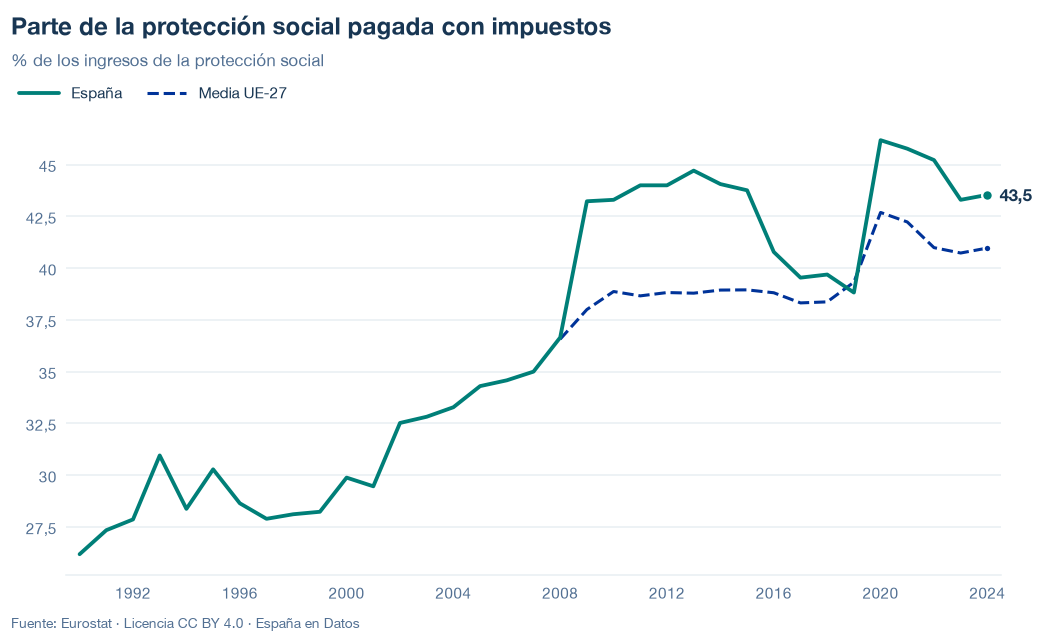

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/financiacion-impuestos-proteccion-social.json y data/financiacion-impuestos-proteccion-social.csv


## 6. Fuentes, notas y licencia

- Eurostat, `spr_rec_sumt` (ESSPROS): `GOV_GEN` (serie de la gráfica) y, para el desglose, `GOV_GEN_EM`, `GOV_GEN_REVGEN`, `SCO`, `SCO_EMPL` y `SCO_PER_PRO`, en `PC_REC`.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.